<a href="https://colab.research.google.com/github/RiyaSunil28/nitinternship/blob/main/Week7_nit.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q open_clip_torch ftfy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 24.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 5.1 MB/s eta 0:00:00


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import open_clip

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from itertools import product

from torchvision import datasets
from torch.utils.data import DataLoader, Subset

from sklearn.metrics import roc_auc_score
from sklearn.manifold import TSNE

In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"

print("Using device:", device)

Using device: cuda


In [ ]:
model, _, preprocess = open_clip.create_model_and_transforms(
    "ViT-B-32",
    pretrained="openai"
)

tokenizer = open_clip.get_tokenizer("ViT-B-32")

model = model.to(device)
model.eval()

for param in model.parameters():
    param.requires_grad = False

logit_scale = model.logit_scale.exp().detach()

print("CLIP loaded and frozen")

open_clip_model.safetensors:   0%|          | 0.00/605M [00:00<?, ?B/s]

/usr/local/lib/python3.12/dist-packages/open_clip/factory.py:450: UserWarning: QuickGELU mismatch between final model config (quick_gelu=False) and pretrained tag 'openai' (quick_gelu=True).
  warnings.warn(


CLIP loaded and frozen


In [ ]:
!mkdir -p data
!rm -f data/cifar-10-python.tar.gz data/cifar-100-python.tar.gz
!wget -q https://data.brainchip.com/dataset-mirror/cifar10/cifar-10-python.tar.gz -P data
!wget -q https://data.brainchip.com/dataset-mirror/cifar100/cifar-100-python.tar.gz -P data
!ls -lh data

total 324M
-rw-r--r-- 1 root root 162M Jul  7  2022 cifar-100-python.tar.gz
-rw-r--r-- 1 root root 163M Jul  7  2022 cifar-10-python.tar.gz


In [ ]:
train_dataset = datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=preprocess
)

test_dataset = datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=preprocess
)

# a copy without any transform, used only to display raw images
test_raw = datasets.CIFAR10(
    root="./data",
    train=False,
    download=True
)

cifar100_test = datasets.CIFAR100(
    root="./data",
    train=False,
    download=True,
    transform=preprocess
)

In [ ]:
class_names = train_dataset.classes

known_classes = [0, 1, 3, 5, 7]
unknown_classes = [2, 4, 6, 8, 9]

known_names = [class_names[i] for i in known_classes]
unknown_names = [class_names[i] for i in unknown_classes]

print("Known:", known_names)
print("Unknown:", unknown_names)

Known: ['airplane', 'automobile', 'cat', 'dog', 'horse']
Unknown: ['bird', 'deer', 'frog', 'ship', 'truck']


In [ ]:
known_train_indices = [
    i for i, label in enumerate(train_dataset.targets)
    if label in known_classes
]

known_test_indices = [
    i for i, label in enumerate(test_dataset.targets)
    if label in known_classes
]

unknown_test_indices = [
    i for i, label in enumerate(test_dataset.targets)
    if label in unknown_classes
]

print("Known train:", len(known_train_indices))
print("Known test:", len(known_test_indices))
print("Unknown test:", len(unknown_test_indices))

Known train: 25000
Known test: 5000
Unknown test: 5000


In [ ]:
def extract_features(dataset, indices=None):

    if indices is not None:
        dataset = Subset(dataset, indices)

    loader = DataLoader(
        dataset,
        batch_size=256,
        shuffle=False,
        num_workers=2
    )

    all_features = []
    all_labels = []

    with torch.no_grad():

        for images, labels in loader:

            features = model.encode_image(images.to(device))

            features = features / features.norm(
                dim=-1,
                keepdim=True
            )

            all_features.append(features.cpu())
            all_labels.append(labels)

    return torch.cat(all_features), torch.cat(all_labels)

In [ ]:
known_train_features, known_train_labels = extract_features(
    train_dataset,
    known_train_indices
)

known_test_features, known_test_labels = extract_features(
    test_dataset,
    known_test_indices
)

unknown_test_features, unknown_test_labels = extract_features(
    test_dataset,
    unknown_test_indices
)

val_unknown_features, _ = extract_features(
    cifar100_test,
    list(range(5000))
)

print("All features extracted")

All features extracted


In [ ]:
generator = torch.Generator().manual_seed(42)

perm = torch.randperm(
    known_train_features.shape[0],
    generator=generator
)

split = int(0.8 * len(perm))

fit_idx = perm[:split]
val_idx = perm[split:]

fit_features = known_train_features[fit_idx]

fit_targets = torch.tensor([
    known_classes.index(int(l))
    for l in known_train_labels[fit_idx]
])

val_known_features = known_train_features[val_idx]

In [ ]:
prompts = [
    f"a photo of a {name}"
    for name in known_names
]

text_tokens = tokenizer(prompts).to(device)

with torch.no_grad():

    base_text = model.encode_text(text_tokens)

    base_text = base_text / base_text.norm(
        dim=-1,
        keepdim=True
    )

prompt_vectors = nn.Parameter(
    torch.randn(
        len(known_classes),
        base_text.shape[1],
        device=device
    ) * 0.01
)

optimizer = optim.Adam([prompt_vectors], lr=1e-3)

criterion = nn.CrossEntropyLoss()

fit_features_device = fit_features.to(device)
fit_targets_device = fit_targets.to(device)

batch_size = 512

for epoch in range(10):

    epoch_perm = torch.randperm(fit_features_device.shape[0])

    for start in range(0, len(epoch_perm), batch_size):

        batch_idx = epoch_perm[start:start + batch_size]

        adapted_text = base_text + prompt_vectors

        adapted_text = adapted_text / adapted_text.norm(
            dim=-1,
            keepdim=True
        )

        logits = (
            logit_scale
            * fit_features_device[batch_idx]
            @ adapted_text.T
        )

        loss = criterion(logits, fit_targets_device[batch_idx])

        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

with torch.no_grad():

    tuned_text = base_text + prompt_vectors

    tuned_text = tuned_text / tuned_text.norm(
        dim=-1,
        keepdim=True
    )

print("Prompt tuning done")

Prompt tuning done


In [ ]:
centroids = []

for class_idx in range(len(known_classes)):

    class_features = fit_features[fit_targets == class_idx]

    centroid = class_features.mean(dim=0)

    centroid = centroid / centroid.norm()

    centroids.append(centroid)

centroids = torch.stack(centroids).to(device)


def compute_scores(image_features, text_features):

    image_features = image_features.to(device)

    with torch.no_grad():

        similarities = image_features @ text_features.T

        logits = logit_scale * similarities

        energy = torch.logsumexp(logits, dim=1)

        top2 = similarities.topk(2, dim=1).values

        margin = top2[:, 0] - top2[:, 1]

        centroid_similarity = (
            image_features @ centroids.T
        ).max(dim=1).values

        predictions = similarities.argmax(dim=1).cpu()

    return (
        energy.cpu().numpy(),
        margin.cpu().numpy(),
        centroid_similarity.cpu().numpy(),
        predictions
    )

In [ ]:
val_known_raw = compute_scores(val_known_features, tuned_text)[:3]
val_unknown_raw = compute_scores(val_unknown_features, tuned_text)[:3]

means = [s.mean() for s in val_known_raw]
stds = [s.std() for s in val_known_raw]

def normalize(raw):
    return [
        (raw[i] - means[i]) / stds[i]
        for i in range(3)
    ]

def fuse(norm_scores, weights):
    return sum(w * s for w, s in zip(weights, norm_scores))

weight_values = [0.0, 0.25, 0.5, 0.75, 1.0]

best_weights = None
best_auroc = 0

val_known_norm = normalize(val_known_raw)
val_unknown_norm = normalize(val_unknown_raw)

for a, b, c in product(weight_values, repeat=3):

    if a + b + c == 0:
        continue

    total = a + b + c

    weights = (a / total, b / total, c / total)

    labels = np.concatenate([
        np.ones(len(val_known_norm[0])),
        np.zeros(len(val_unknown_norm[0]))
    ])

    scores = np.concatenate([
        fuse(val_known_norm, weights),
        fuse(val_unknown_norm, weights)
    ])

    auroc = roc_auc_score(labels, scores)

    if auroc > best_auroc:
        best_auroc = auroc
        best_weights = weights

print("Fusion weights:", tuple(round(w, 3) for w in best_weights))

Fusion weights: (0.5, 0.25, 0.25)


In [ ]:
known_energy, known_margin, known_dist, known_preds = compute_scores(
    known_test_features,
    tuned_text
)

unknown_energy, unknown_margin, unknown_dist, unknown_preds = compute_scores(
    unknown_test_features,
    tuned_text
)

known_fused = fuse(
    normalize((known_energy, known_margin, known_dist)),
    best_weights
)

unknown_fused = fuse(
    normalize((unknown_energy, unknown_margin, unknown_dist)),
    best_weights
)

print("Test scores ready")

Test scores ready


In [ ]:
rng = np.random.default_rng(42)

known_sample = rng.choice(
    len(known_test_features),
    2000,
    replace=False
)

unknown_sample = rng.choice(
    len(unknown_test_features),
    2000,
    replace=False
)

tsne_input = torch.cat([
    known_test_features[known_sample],
    unknown_test_features[unknown_sample]
]).numpy()

tsne = TSNE(
    n_components=2,
    perplexity=30,
    random_state=42
)

embedding = tsne.fit_transform(tsne_input)

print("t-SNE done:", embedding.shape)

t-SNE done: (4000, 2)


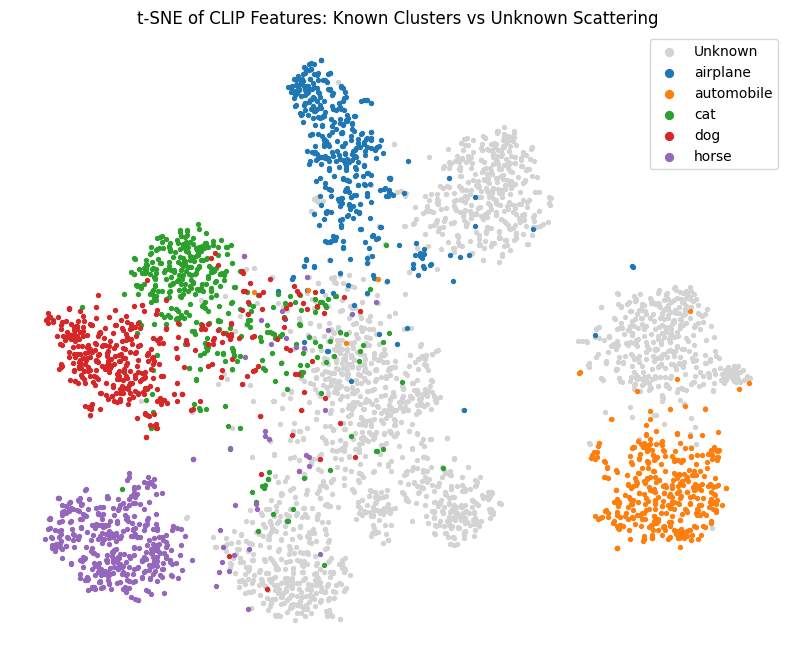

In [ ]:
known_2d = embedding[:2000]
unknown_2d = embedding[2000:]

known_sample_labels = known_test_labels[known_sample].numpy()

plt.figure(figsize=(10, 8))

plt.scatter(
    unknown_2d[:, 0],
    unknown_2d[:, 1],
    c="lightgray",
    s=8,
    label="Unknown"
)

for class_idx in known_classes:

    mask = known_sample_labels == class_idx

    plt.scatter(
        known_2d[mask, 0],
        known_2d[mask, 1],
        s=8,
        label=class_names[class_idx]
    )

plt.title("t-SNE of CLIP Features: Known Clusters vs Unknown Scattering")

plt.legend(markerscale=2)

plt.axis("off")

plt.savefig("fig_tsne.png", dpi=200, bbox_inches="tight")

plt.show()

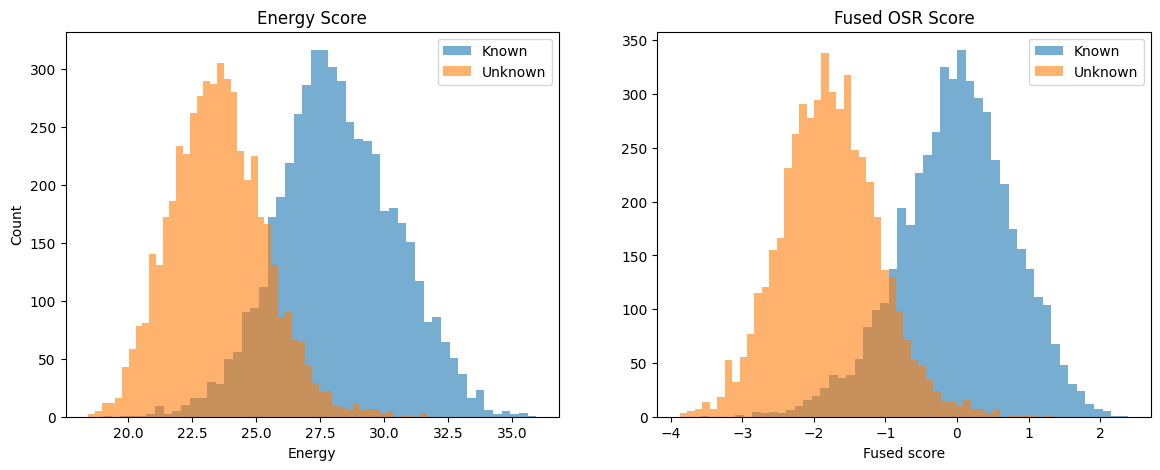

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(known_energy, bins=50, alpha=0.6, label="Known")
axes[0].hist(unknown_energy, bins=50, alpha=0.6, label="Unknown")

axes[0].set_title("Energy Score")
axes[0].set_xlabel("Energy")
axes[0].set_ylabel("Count")
axes[0].legend()

axes[1].hist(known_fused, bins=50, alpha=0.6, label="Known")
axes[1].hist(unknown_fused, bins=50, alpha=0.6, label="Unknown")

axes[1].set_title("Fused OSR Score")
axes[1].set_xlabel("Fused score")
axes[1].legend()

plt.savefig("fig_score_distributions.png", dpi=200, bbox_inches="tight")

plt.show()

In [ ]:
zs_known = compute_scores(known_test_features, base_text)[:3]
zs_unknown = compute_scores(unknown_test_features, base_text)[:3]

labels = np.concatenate([
    np.ones(len(known_test_features)),
    np.zeros(len(unknown_test_features))
])

def auroc_of(known_scores, unknown_scores):
    return round(
        roc_auc_score(
            labels,
            np.concatenate([known_scores, unknown_scores])
        ),
        4
    )

prompt_effect = pd.DataFrame({
    "Score": ["Energy", "Margin", "Distance"],
    "Zero-Shot AUROC": [
        auroc_of(zs_known[0], zs_unknown[0]),
        auroc_of(zs_known[1], zs_unknown[1]),
        auroc_of(zs_known[2], zs_unknown[2])
    ],
    "Prompt-Tuned AUROC": [
        auroc_of(known_energy, unknown_energy),
        auroc_of(known_margin, unknown_margin),
        auroc_of(known_dist, unknown_dist)
    ]
})

prompt_effect.to_csv("table_prompt_effect.csv", index=False)

prompt_effect

,Score,Zero-Shot AUROC,Prompt-Tuned AUROC
0,Energy,0.9026,0.9443
1,Margin,0.8647,0.8651
2,Distance,0.8697,0.8697


In [ ]:
threshold = np.percentile(known_fused, 5)

print("Threshold (95% known acceptance):", round(threshold, 4))

unknown_true_names = [
    class_names[int(l)]
    for l in unknown_test_labels
]

accepted = unknown_fused > threshold

failure_rows = []

for name in unknown_names:

    mask = np.array([n == name for n in unknown_true_names])

    failure_rows.append({
        "Unknown class": name,
        "Mean fused score": round(unknown_fused[mask].mean(), 4),
        "Accepted as known (%)": round(
            100 * accepted[mask].mean(),
            2
        )
    })

failure_table = pd.DataFrame(failure_rows).sort_values(
    "Accepted as known (%)",
    ascending=False
)

failure_table.to_csv("table_failure_cases.csv", index=False)

failure_table

Threshold (95% known acceptance): -1.3436


,Unknown class,Mean fused score,Accepted as known (%)
2,frog,-1.3638,48.2
4,truck,-1.5999,28.1
1,deer,-1.8780,17.2
0,bird,-2.0070,16.2
3,ship,-2.0472,14.2


In [ ]:
# for the unknowns that slipped through:
# which known class were they predicted as?

confusion = pd.crosstab(
    pd.Series(
        [unknown_true_names[i] for i in np.where(accepted)[0]],
        name="True unknown class"
    ),
    pd.Series(
        [
            known_names[int(unknown_preds[i])]
            for i in np.where(accepted)[0]
        ],
        name="Predicted known class"
    )
)

confusion.to_csv("table_unknown_confusion.csv")

confusion

Predicted known class,airplane,automobile,cat,dog,horse
True unknown class,,,,,
bird,46,0,91,15,10
deer,5,1,76,20,70
frog,3,1,471,6,1
ship,130,12,0,0,0
truck,13,268,0,0,0


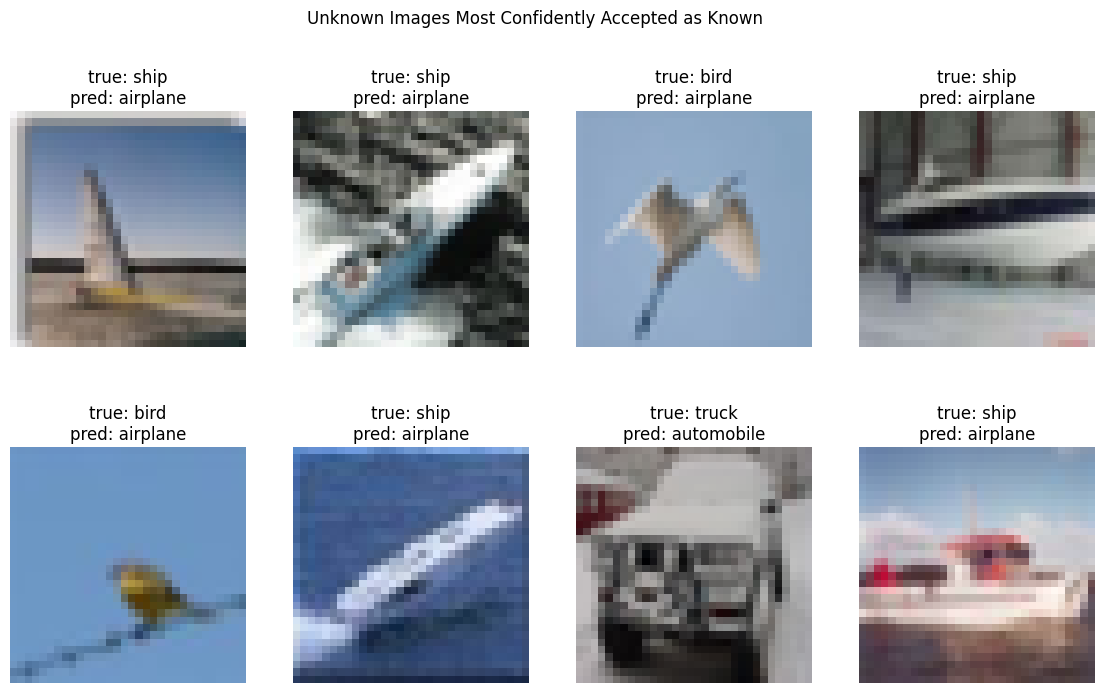

In [ ]:
hardest = np.argsort(unknown_fused)[::-1][:8]

fig, axes = plt.subplots(2, 4, figsize=(14, 8))

for ax, idx in zip(axes.flat, hardest):

    original_index = unknown_test_indices[idx]

    image, label = test_raw[original_index]

    ax.imshow(image)

    ax.set_title(
        f"true: {class_names[label]}\n"
        f"pred: {known_names[int(unknown_preds[idx])]}"
    )

    ax.axis("off")

plt.suptitle("Unknown Images Most Confidently Accepted as Known")

plt.savefig("fig_hardest_unknowns.png", dpi=200, bbox_inches="tight")

plt.show()

In [ ]:
print("Saved files:")
print("  fig_tsne.png")
print("  fig_score_distributions.png")
print("  fig_hardest_unknowns.png")
print("  table_prompt_effect.csv")
print("  table_failure_cases.csv")
print("  table_unknown_confusion.csv")

Saved files:
  fig_tsne.png
  fig_score_distributions.png
  fig_hardest_unknowns.png
  table_prompt_effect.csv
  table_failure_cases.csv
  table_unknown_confusion.csv
